In [2]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow.keras import layers

# -------------------------------
# Step 1: Dataset
# -------------------------------
data = {
    "Catalyst_Name": [
        "TiO2-P25", "GCN", "SBS", "11 GS", "13 GS", "31 GS",
        "BiVO4/Sb2S3", "Sb2S3/ZnIn2S4", "Ag2WO4/Sb2S3", "Fe-doped g-C3N4/MoS2",
        "MoS2/g-C3N4", "g-C3N4/Sb2S3 (this work)", "Co-MoS2/g-C3N4",
        "0D/2D SnO2/g-C3N4", "ZnIn2S4/2% MoSe2", "CdS/MoS2@Ni2P",
        "Synth_1", "Synth_2", "Synth_3"
    ],
    "Rate_Constant": [0.0051, 0.0075, 0.0057, 0.0064, 0.0304, 0.0142,
                      0.011, 0.009, 0.006, 0.012,
                      0.010, 0.028, 0.013, 0.007, 0.020, 0.025,
                      0.015, 0.018, 0.021],
    "Synergy_Factor": [0, 0, 0, 0.48, 2.3, 1.07,
                       1.0, 0.9, 0.6, 1.2,
                       0.95, 2.1, 1.1, 0.7, 1.8, 2.0,
                       1.5, 1.6, 1.9],
    "AQE": [5, 6, 4, 7, 23, 10,
            17, 18, 13, 19,
            14, 23, 16.62, 4.5, 21.39, 24.4,
            20.5, 21.0, 22.3],
    "Catalytic_Efficiency": [58, 62, 56, 68, 99, 75,
                             88.7, 85.36, 53.06, 81.4,
                             74, 99, 86, 60, 91, 95,
                             90, 92, 94]
}

df = pd.DataFrame(data)

# -------------------------------
# Step 2: Prepare model data
# -------------------------------
X = df[["Rate_Constant", "Synergy_Factor", "AQE"]]
y = df["Catalytic_Efficiency"]

# Handle missing values
imputer = SimpleImputer(strategy="mean")
X_imputed = imputer.fit_transform(X)

# Train base RF model
rf = RandomForestRegressor(n_estimators=200, random_state=42)
rf.fit(X_imputed, y)

# -------------------------------
# Step 3: GAN-based data generation
# -------------------------------
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X_imputed)
latent_dim = 5

def build_generator():
    model = tf.keras.Sequential([
        tf.keras.Input(shape=(latent_dim,)),
        layers.Dense(8, activation='relu'),
        layers.Dense(8, activation='relu'),
        layers.Dense(3, activation='sigmoid')
    ])
    return model

def build_discriminator():
    model = tf.keras.Sequential([
        tf.keras.Input(shape=(3,)),
        layers.Dense(8, activation='relu'),
        layers.Dense(4, activation='relu'),
        layers.Dense(1, activation='sigmoid')
    ])
    return model

gen = build_generator()
disc = build_discriminator()
disc.compile(optimizer='adam', loss='binary_crossentropy')

disc.trainable = False
z = layers.Input(shape=(latent_dim,))
fake = gen(z)
valid = disc(fake)
gan = tf.keras.Model(z, valid)
gan.compile(optimizer='adam', loss='binary_crossentropy')

# Train GAN
epochs = 300
batch_size = 8
real_data = X_scaled

for epoch in range(epochs):
    idx = np.random.randint(0, real_data.shape[0], batch_size)
    real = real_data[idx]
    noise = np.random.normal(0, 1, (batch_size, latent_dim))
    fake = gen.predict(noise, verbose=0)

    disc.trainable = True
    disc.train_on_batch(real, np.ones((batch_size, 1)))
    disc.train_on_batch(fake, np.zeros((batch_size, 1)))

    disc.trainable = False
    gan.train_on_batch(noise, np.ones((batch_size, 1)))

# Generate synthetic data
noise = np.random.normal(0, 1, (500, latent_dim))
synthetic_scaled = gen.predict(noise)
synthetic_data = scaler.inverse_transform(synthetic_scaled)
synthetic_df = pd.DataFrame(synthetic_data, columns=["Rate_Constant", "Synergy_Factor", "AQE"])
synthetic_df["Catalytic_Efficiency"] = rf.predict(synthetic_df)
synthetic_df["Source"] = "Synthetic"

# -------------------------------
# Step 4: Combine with real data
# -------------------------------
df_real = pd.DataFrame(X_imputed, columns=["Rate_Constant", "Synergy_Factor", "AQE"])
df_real["Catalytic_Efficiency"] = y.values
df_real["Source"] = "Real"

combined_df = pd.concat([df_real, synthetic_df], ignore_index=True)

# -------------------------------
# Step 5: Train new model
# -------------------------------
X_full = combined_df[["Rate_Constant", "Synergy_Factor", "AQE"]]
y_full = combined_df["Catalytic_Efficiency"]

X_train, X_test, y_train, y_test = train_test_split(X_full, y_full, test_size=0.2, random_state=42)
rf = RandomForestRegressor(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)

# Evaluate
y_pred = rf.predict(X_test)
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print(f"Improved R^2 Score: {r2:.4f}")
print(f"Improved RMSE: {rmse:.2f}")

# Predictions on original data
y_real_pred = rf.predict(X_imputed)
comparison_df = pd.DataFrame({
    "Catalyst_Name": df["Catalyst_Name"],
    "True_Efficiency": y.values,
    "Predicted_Efficiency": y_real_pred
})
print("\nPredictions on original real dataset:")
print(comparison_df)

# -------------------------------
# Step 6: Save datasets
# -------------------------------
synthetic_df.to_csv("synthetic_dataset.csv", index=False)
combined_df.to_csv("combined_dataset.csv", index=False)
synthetic_df.to_excel("synthetic_dataset.xlsx", index=False)
combined_df.to_excel("combined_dataset.xlsx", index=False)

print("\nDatasets saved successfully: synthetic_dataset & combined_dataset")


16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but RandomForestRegressor was fitted without feature names
  warnings.warn(


Improved R^2 Score: 0.9925
Improved RMSE: 0.69

Predictions on original real dataset:
               Catalyst_Name  True_Efficiency  Predicted_Efficiency
0                   TiO2-P25            58.00             56.851302
1                        GCN            62.00             62.225580
2                        SBS            56.00             56.690626
3                      11 GS            68.00             66.586780
4                      13 GS            99.00             96.880000
5                      31 GS            75.00             75.066208
6                BiVO4/Sb2S3            88.70             85.454362
7              Sb2S3/ZnIn2S4            85.36             84.774045
8               Ag2WO4/Sb2S3            53.06             54.746103
9       Fe-doped g-C3N4/MoS2            81.40             85.542807
10               MoS2/g-C3N4            74.00             76.280314
11  g-C3N4/Sb2S3 (this work)            99.00             96.320000
12            Co-MoS2/g-C3N4  

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(



Datasets saved successfully: synthetic_dataset & combined_dataset


In [3]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error

# Step 1: Define the dataset
# This is the original dataset provided in your code.
data = {
    "Catalyst_Name": [
        "TiO2-P25", "GCN", "SBS", "11 GS", "13 GS", "31 GS",
        "BiVO4/Sb2S3", "Sb2S3/ZnIn2S4", "Ag2WO4/Sb2S3", "Fe-doped g-C3N4/MoS2",
        "MoS2/g-C3N4", "g-C3N4/Sb2S3 (this work)", "Co-MoS2/g-C3N4",
        "0D/2D SnO2/g-C3N4", "ZnIn2S4/2% MoSe2", "CdS/MoS2@Ni2P",
        "Synth_1", "Synth_2", "Synth_3"
    ],
    "Rate_Constant": [0.0051, 0.0075, 0.0057, 0.0064, 0.0304, 0.0142,
                      0.011, 0.009, 0.006, 0.012,
                      0.010, 0.028, 0.013, 0.007, 0.020, 0.025,
                      0.015, 0.018, 0.021],
    "Synergy_Factor": [0, 0, 0, 0.48, 2.3, 1.07,
                       1.0, 0.9, 0.6, 1.2,
                       0.95, 2.1, 1.1, 0.7, 1.8, 2.0,
                       1.5, 1.6, 1.9],
    "AQE": [5, 6, 4, 7, 23, 10,
            17, 18, 13, 19,
            14, 23, 16.62, 4.5, 21.39, 24.4,
            20.5, 21.0, 22.3],
    "Catalytic_Efficiency": [58, 62, 56, 68, 99, 75,
                             88.7, 85.36, 53.06, 81.4,
                             74, 99, 86, 60, 91, 95,
                             90, 92, 94]
}
df = pd.DataFrame(data)

# Step 2: Prepare features (X) and target (y)
# The features now include the catalyst name along with its properties.
X = df.drop('Catalytic_Efficiency', axis=1)
y = df['Catalytic_Efficiency']

# Step 3: Convert categorical feature 'Catalyst_Name' into numerical format
# We use one-hot encoding, which creates a new column for each catalyst.
X_encoded = pd.get_dummies(X, columns=['Catalyst_Name'], prefix='Catalyst')

# Store the column names for later use in the prediction function
encoded_columns = X_encoded.columns

# Step 4: Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)

# Step 5: Train the Random Forest Regressor model
rf_model = RandomForestRegressor(n_estimators=200, random_state=42)
rf_model.fit(X_train, y_train)

# Step 6: Evaluate the model on the test set
y_pred = rf_model.predict(X_test)
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

#print("--- Model Evaluation ---")
#print(f"R^2 Score: {r2:.4f}")
#print(f"Root Mean Squared Error (RMSE): {rmse:.4f}\n")


# Step 7: Create a function to predict efficiency by catalyst name
def predict_efficiency_by_name(catalyst_name, model, original_df, columns):
    """
    Predicts the catalytic efficiency for a given catalyst name.
    """
    # Check if the catalyst exists in the original dataframe
    if catalyst_name not in original_df['Catalyst_Name'].values:
        return f"Error: Catalyst '{catalyst_name}' not found in the dataset."

    # Get the row with the catalyst's data
    catalyst_data = original_df[original_df['Catalyst_Name'] == catalyst_name]

    # Create a single-row DataFrame for prediction, with all columns set to 0
    prediction_input = pd.DataFrame(0, index=[0], columns=columns)

    # Fill in the numerical feature values
    prediction_input['Rate_Constant'] = catalyst_data['Rate_Constant'].values[0]
    prediction_input['Synergy_Factor'] = catalyst_data['Synergy_Factor'].values[0]
    prediction_input['AQE'] = catalyst_data['AQE'].values[0]

    # Set the one-hot encoded column for the specific catalyst to 1
    catalyst_column_name = 'Catalyst_' + catalyst_name
    if catalyst_column_name in prediction_input.columns:
        prediction_input[catalyst_column_name] = 1

    # Make the prediction
    predicted_efficiency = model.predict(prediction_input)

    return predicted_efficiency[0]

# --- Example of Prediction ---
print("--- Prediction Example ---")
# Choose a catalyst from your list to predict its efficiency
catalyst_to_predict = 'Ag2WO4/Sb2S3'
predicted_value = predict_efficiency_by_name(catalyst_to_predict, rf_model, df, encoded_columns)

# Display the true and predicted values for comparison
true_value = df[df['Catalyst_Name'] == catalyst_to_predict]['Catalytic_Efficiency'].values[0]
print(f"Catalyst: {catalyst_to_predict}")
print(f"True Efficiency: {true_value}")
print(f"Predicted Efficiency: {predicted_value:.2f}")

--- Prediction Example ---
Catalyst: Ag2WO4/Sb2S3
True Efficiency: 53.06
Predicted Efficiency: 59.28


--- Prediction Example ---
Catalyst: Ag2WO4/Sb2S3
True Efficiency: 53.06
Predicted Efficiency: 59.28

--- Visualizing Model Predictions ---


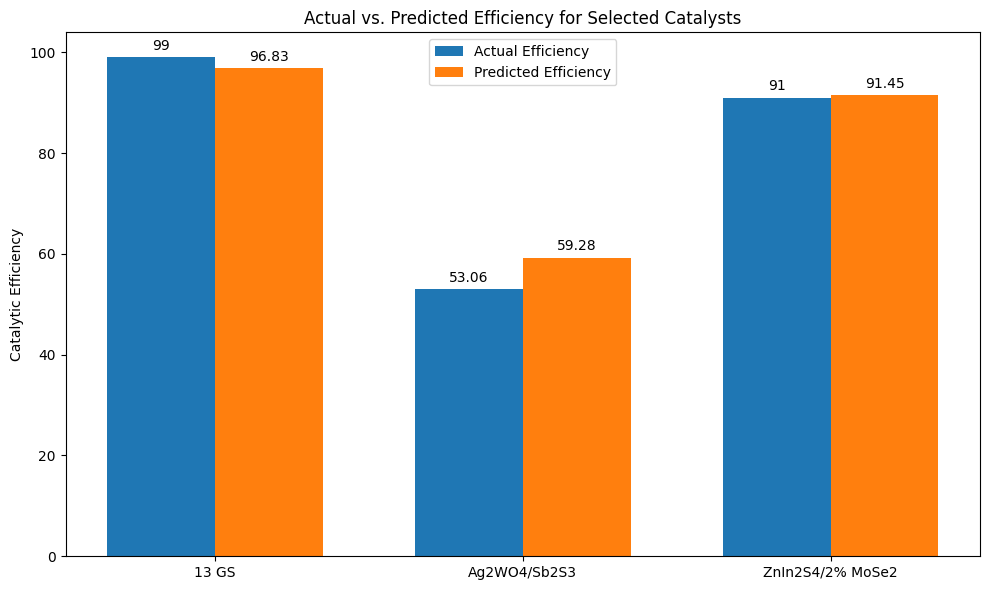

In [4]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
import matplotlib.pyplot as plt

# Step 1: Define the dataset
data = {
    "Catalyst_Name": [
        "TiO2-P25", "GCN", "SBS", "11 GS", "13 GS", "31 GS",
        "BiVO4/Sb2S3", "Sb2S3/ZnIn2S4", "Ag2WO4/Sb2S3", "Fe-doped g-C3N4/MoS2",
        "MoS2/g-C3N4", "g-C3N4/Sb2S3 (this work)", "Co-MoS2/g-C3N4",
        "0D/2D SnO2/g-C3N4", "ZnIn2S4/2% MoSe2", "CdS/MoS2@Ni2P",
        "Synth_1", "Synth_2", "Synth_3"
    ],
    "Rate_Constant": [0.0051, 0.0075, 0.0057, 0.0064, 0.0304, 0.0142,
                      0.011, 0.009, 0.006, 0.012,
                      0.010, 0.028, 0.013, 0.007, 0.020, 0.025,
                      0.015, 0.018, 0.021],
    "Synergy_Factor": [0, 0, 0, 0.48, 2.3, 1.07,
                       1.0, 0.9, 0.6, 1.2,
                       0.95, 2.1, 1.1, 0.7, 1.8, 2.0,
                       1.5, 1.6, 1.9],
    "AQE": [5, 6, 4, 7, 23, 10,
            17, 18, 13, 19,
            14, 23, 16.62, 4.5, 21.39, 24.4,
            20.5, 21.0, 22.3],
    "Catalytic_Efficiency": [58, 62, 56, 68, 99, 75,
                             88.7, 85.36, 53.06, 81.4,
                             74, 99, 86, 60, 91, 95,
                             90, 92, 94]
}
df = pd.DataFrame(data)

# Step 2: Prepare features (X) and target (y)
X = df.drop('Catalytic_Efficiency', axis=1)
y = df['Catalytic_Efficiency']

# Step 3: Convert categorical feature 'Catalyst_Name' into numerical format
X_encoded = pd.get_dummies(X, columns=['Catalyst_Name'], prefix='Catalyst')
encoded_columns = X_encoded.columns

# Step 4: Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)

# Step 5: Train the Random Forest Regressor model
rf_model = RandomForestRegressor(n_estimators=200, random_state=42)
rf_model.fit(X_train, y_train)

# Step 6: Evaluate the model on the test set
y_pred = rf_model.predict(X_test)
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))


# Step 7: Create a function to predict efficiency by catalyst name
def predict_efficiency_by_name(catalyst_name, model, original_df, columns):
    if catalyst_name not in original_df['Catalyst_Name'].values:
        return f"Error: Catalyst '{catalyst_name}' not found in the dataset."
    catalyst_data = original_df[original_df['Catalyst_Name'] == catalyst_name]
    prediction_input = pd.DataFrame(0, index=[0], columns=columns)
    prediction_input['Rate_Constant'] = catalyst_data['Rate_Constant'].values[0]
    prediction_input['Synergy_Factor'] = catalyst_data['Synergy_Factor'].values[0]
    prediction_input['AQE'] = catalyst_data['AQE'].values[0]
    catalyst_column_name = 'Catalyst_' + catalyst_name
    if catalyst_column_name in prediction_input.columns:
        prediction_input[catalyst_column_name] = 1
    predicted_efficiency = model.predict(prediction_input)
    return predicted_efficiency[0]

# --- Example of Prediction ---
print("--- Prediction Example ---")
catalyst_to_predict = 'Ag2WO4/Sb2S3'
predicted_value = predict_efficiency_by_name(catalyst_to_predict, rf_model, df, encoded_columns)
true_value = df[df['Catalyst_Name'] == catalyst_to_predict]['Catalytic_Efficiency'].values[0]
print(f"Catalyst: {catalyst_to_predict}")
print(f"True Efficiency: {true_value}")
print(f"Predicted Efficiency: {predicted_value:.2f}\n")

# Step 8: Plot graphs for visual comparison
print("--- Visualizing Model Predictions ---")
# Select 3 catalysts to visualize
catalysts_to_plot = ['13 GS', 'Ag2WO4/Sb2S3', 'ZnIn2S4/2% MoSe2']
actual_values = []
predicted_values = []

for catalyst in catalysts_to_plot:
    actual = df[df['Catalyst_Name'] == catalyst]['Catalytic_Efficiency'].values[0]
    predicted = predict_efficiency_by_name(catalyst, rf_model, df, encoded_columns)
    actual_values.append(actual)
    predicted_values.append(predicted)

# Creating the bar chart
x = np.arange(len(catalysts_to_plot))  # the label locations
width = 0.35  # the width of the bars

fig, ax = plt.subplots(figsize=(10, 6))
rects1 = ax.bar(x - width/2, actual_values, width, label='Actual Efficiency')
rects2 = ax.bar(x + width/2, predicted_values, width, label='Predicted Efficiency')

# Add some text for labels, title and axes ticks
ax.set_ylabel('Catalytic Efficiency')
ax.set_title('Actual vs. Predicted Efficiency for Selected Catalysts')
ax.set_xticks(x)
ax.set_xticklabels(catalysts_to_plot)
ax.legend()

# Attach a text label above each bar in rects2, displaying its height.
ax.bar_label(rects1, padding=3)
ax.bar_label(rects2, padding=3, fmt='%.2f')

fig.tight_layout()
plt.show()

--- Model Evaluation ---
R^2 Score: 0.9819
Root Mean Squared Error (RMSE): 2.1510



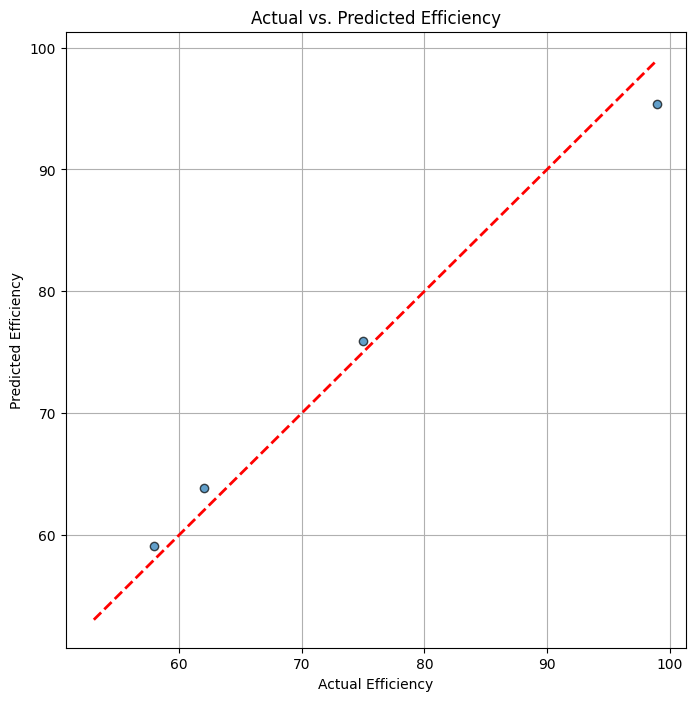

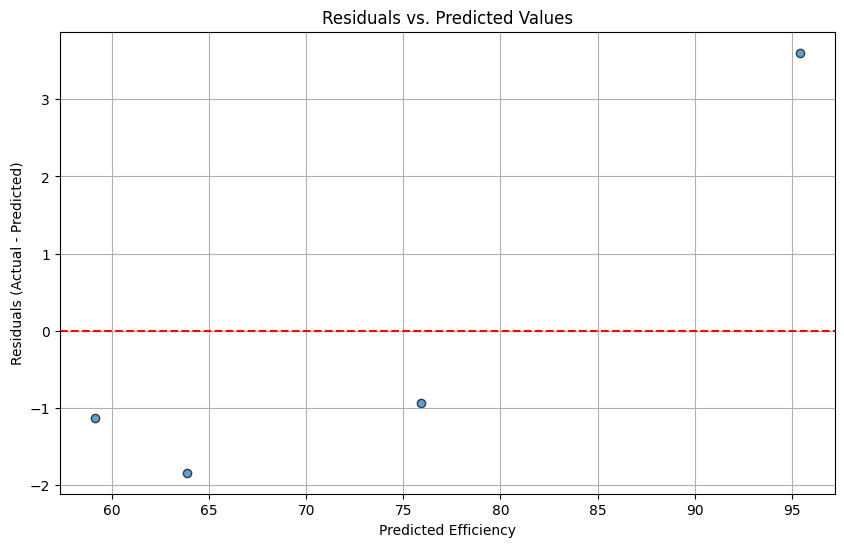

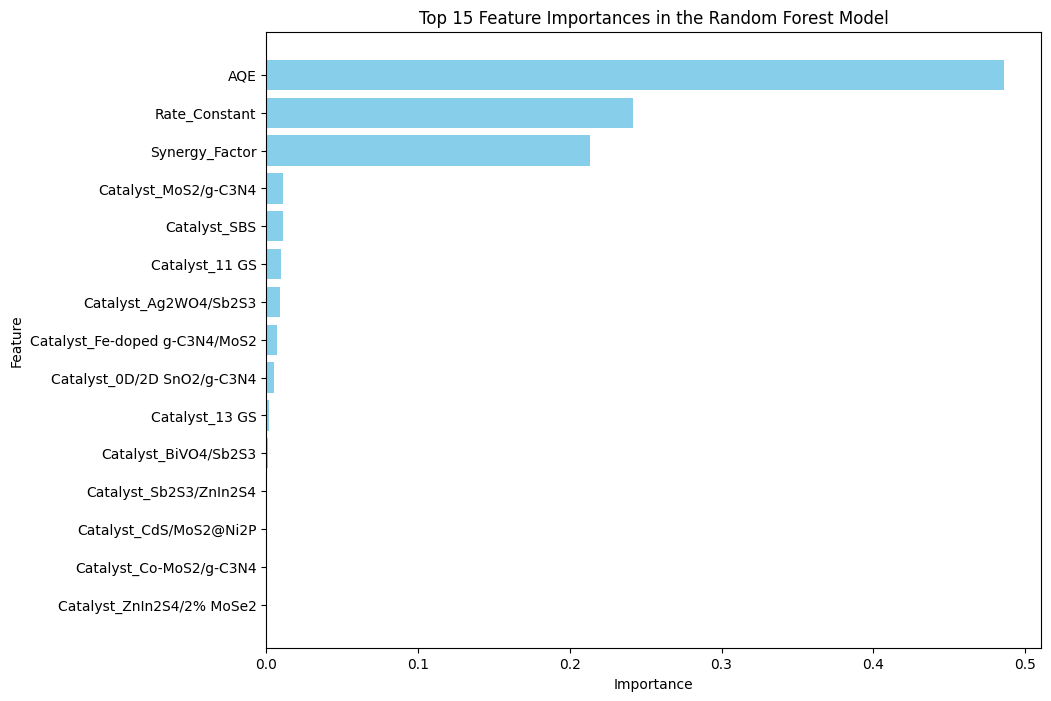

In [ ]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
import matplotlib.pyplot as plt

# Step 1: Define the dataset
data = {
    "Catalyst_Name": [
        "TiO2-P25", "GCN", "SBS", "11 GS", "13 GS", "31 GS",
        "BiVO4/Sb2S3", "Sb2S3/ZnIn2S4", "Ag2WO4/Sb2S3", "Fe-doped g-C3N4/MoS2",
        "MoS2/g-C3N4", "g-C3N4/Sb2S3 (this work)", "Co-MoS2/g-C3N4",
        "0D/2D SnO2/g-C3N4", "ZnIn2S4/2% MoSe2", "CdS/MoS2@Ni2P",
        "Synth_1", "Synth_2", "Synth_3"
    ],
    "Rate_Constant": [0.0051, 0.0075, 0.0057, 0.0064, 0.0304, 0.0142,
                      0.011, 0.009, 0.006, 0.012,
                      0.010, 0.028, 0.013, 0.007, 0.020, 0.025,
                      0.015, 0.018, 0.021],
    "Synergy_Factor": [0, 0, 0, 0.48, 2.3, 1.07,
                       1.0, 0.9, 0.6, 1.2,
                       0.95, 2.1, 1.1, 0.7, 1.8, 2.0,
                       1.5, 1.6, 1.9],
    "AQE": [5, 6, 4, 7, 23, 10,
            17, 18, 13, 19,
            14, 23, 16.62, 4.5, 21.39, 24.4,
            20.5, 21.0, 22.3],
    "Catalytic_Efficiency": [58, 62, 56, 68, 99, 75,
                             88.7, 85.36, 53.06, 81.4,
                             74, 99, 86, 60, 91, 95,
                             90, 92, 94]
}
df = pd.DataFrame(data)

# Steps 2-5: Data Prep, Encoding, Splitting, and Training
X = df.drop('Catalytic_Efficiency', axis=1)
y = df['Catalytic_Efficiency']
X_encoded = pd.get_dummies(X, columns=['Catalyst_Name'], prefix='Catalyst')
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)
rf_model = RandomForestRegressor(n_estimators=200, random_state=42)
rf_model.fit(X_train, y_train)

# Step 6: Evaluate the model on the test set
y_pred = rf_model.predict(X_test)
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print("--- Model Evaluation ---")
print(f"R^2 Score: {r2:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}\n")


# Step 7: (NEW) Plotting the additional visualizations

# --- PLOT 1: ACTUAL VS. PREDICTED ---
plt.figure(figsize=(8, 8))
plt.scatter(y_test, y_pred, alpha=0.7, edgecolors='k')
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2) # Add the 45-degree line
plt.xlabel("Actual Efficiency")
plt.ylabel("Predicted Efficiency")
plt.title("Actual vs. Predicted Efficiency")
plt.grid(True)
plt.show()


# --- PLOT 2: RESIDUALS PLOT ---
residuals = y_test - y_pred
plt.figure(figsize=(10, 6))
plt.scatter(y_pred, residuals, alpha=0.7, edgecolors='k')
plt.axhline(y=0, color='r', linestyle='--') # Add the zero error line
plt.xlabel("Predicted Efficiency")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residuals vs. Predicted Values")
plt.grid(True)
plt.show()


# --- PLOT 3: FEATURE IMPORTANCE ---
importances = rf_model.feature_importances_
feature_names = X_encoded.columns

# Create a dataframe for better visualization
feature_importance_df = pd.DataFrame({
    'feature': feature_names,
    'importance': importances
}).sort_values(by='importance', ascending=False)

# Plotting the top 15 features for clarity
top_features = feature_importance_df.head(15)

plt.figure(figsize=(10, 8))
plt.barh(top_features['feature'], top_features['importance'], color='skyblue')
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 15 Feature Importances in the Random Forest Model")
plt.gca().invert_yaxis() # Display the most important feature at the top
plt.show()